# Log-uniform injection: Monte Carlo versus the erf difference
Compare repeated solar-ring samples with the diffusion-limit prediction for $dN_0/dE=C/E$ and $D\propto E^\delta$. Default: the original `proton_earth_t1e8.bin` run, with $\delta=1/3$, $E_{max}=10^6$ GeV, and $t_{end}=10^8$ yr.

The current C++ source has since changed to $\delta=1/2$, $E_{max}=10^7$ GeV and $t_{end}=10^9$ yr. To analyze that run, change the filename and parameters together after its output is available. Binary files contain no run metadata.

These are repeated endpoint samples, not first arrivals. The torus radius is the mean free path and the sampling interval is $\lambda/(2c)$. No observed-count fitting is used below.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

file_name = 'proton_earth_t1e8.bin'
N_particles = 10000
E_min, E_max = 10.0, 1e6  # initial total energy, GeV
delta = 1/3             # lambda proportional to rigidity**delta
t_end = 1e8              # yr
R_earth = 8000.0         # pc
c_pc_yr = 0.30660139
m_p = 0.938272           # rest energy, GeV

data_dir = Path('.')
if not (data_dir / file_name).exists():
    data_dir = Path('age_dist')
arrivals = np.fromfile(data_dir / file_name, dtype='=f8').reshape(-1, 2)
E_arr, time_arr = arrivals.T
if len(arrivals) == 0 or np.any(time_arr <= 0) or np.any(time_arr > t_end):
    raise ValueError('Empty data or ages inconsistent with configured run.')
print('File:', data_dir / file_name)
print('Step samples:', len(arrivals))
print('Energy range [GeV]:', E_arr.min(), E_arr.max())
print('Age range [Myr]:', time_arr.min()/1e6, time_arr.max()/1e6)


File: proton_earth_t1e8.bin
Step samples: 57368
Energy range [GeV]: 10.174211233788414 998849.2549282269
Age range [Myr]: 0.2693705314470719 99.90920305527422


## Absolute normalization
For the thin torus, $V=2\pi^2R_\oplus\lambda^2$, $\Delta t=\lambda/(2c)$, and $D=c\lambda/3$, giving $V/\Delta t=12\pi^2R_\oplus D$.
Using the point-source Green function and $dE/E=dD/(\delta D)$ gives
$$F(t)=\frac{dN_{sample}}{d\ln t}=\frac{3\pi C}{\delta}\left[\operatorname{erf}\sqrt{\frac{b}{D_{min}t}}-\operatorname{erf}\sqrt{\frac{b}{D_{max}t}}\right],$$
where $C=N/\ln(E_{max}/E_{min})$ and $b=R_\oplus^2/4$.

The closed form uses the relativistic approximation $\mathcal R\simeq E$ for protons. The C++ walk uses $\mathcal R=\sqrt{E^2-m_p^2}$. A separate discrete-grid quadrature below retains that exact rigidity to distinguish this approximation from sampling fluctuations. Both references approximate density as constant across the thin torus, and neglect the final shortened-step correction.


In [2]:
C = N_particles/np.log(E_max/E_min)
b = R_earth**2/4
D_min = c_pc_yr*2*(E_min/10)**delta/3
D_max = c_pc_yr*2*(E_max/10)**delta/3


def erf_age(age):
    # erf(x) = 2/sqrt(pi) * integral_0^x exp(-u^2) du.
    # scipy.special.erf evaluates this non-elementary function directly;
    # it is needed for the closed-form diffusion integral, not for data fitting.
    slow = np.sqrt(b/(D_min*age))
    fast = np.sqrt(b/(D_max*age))
    return 3*np.pi*C/delta * (erf(slow)-erf(fast))


t_min = min(1e5, time_arr.min()*0.99)
time_bins = np.logspace(np.log10(t_min), np.log10(t_end), 41)
time_bins[-1] = t_end
time_centers = np.sqrt(time_bins[:-1]*time_bins[1:])
dlnt = np.diff(np.log(time_bins))
counts = np.histogram(time_arr, bins=time_bins)[0]
observed = counts/dlnt

# Integrate F(t) in ln(t) within each bin, then divide by its width.
# This compares bin averages to bin averages rather than point values.
expected_counts = np.zeros(len(counts))
for j in range(len(counts)):
    logt = np.linspace(np.log(time_bins[j]), np.log(time_bins[j+1]), 65)
    values = erf_age(np.exp(logt))
    expected_counts[j] = np.sum((values[1:]+values[:-1])/2*np.diff(logt))
expected = expected_counts/dlnt
print('Observed samples in bins:', counts.sum())
print('Erf prediction in bins:', expected_counts.sum())
print('Transition times b/Dmax, b/Dmin [Myr]:', b/D_max/1e6, b/D_min/1e6)


Observed samples in bins: 57368
Erf prediction in bins: 56131.665841415226
Transition times b/Dmax, b/Dmin [Myr]: 1.686438295689567 78.27753161849658


In [3]:
# Retain the deterministic injection grid and exact proton rigidity.
E_start = np.logspace(np.log10(E_min), np.log10(E_max), N_particles)
rigidity = np.sqrt((E_start-m_p)*(E_start+m_p))
mean_path = 2*(rigidity/10)**delta
D = c_pc_yr*mean_path/3
step_time = mean_path/(2*c_pc_yr)
volume = 2*np.pi**2*R_earth*mean_path**2
weight = volume/step_time
exact_counts = np.zeros(len(counts))
for j in range(len(counts)):
    logt = np.linspace(np.log(time_bins[j]), np.log(time_bins[j+1]), 65)
    values = np.zeros(len(logt))
    for k in range(len(logt)):
        age = np.exp(logt[k])
        G = np.exp(-b/(D*age))/(4*np.pi*D*age)**1.5
        values[k] = age*np.sum(weight*G)
    exact_counts[j] = np.sum((values[1:]+values[:-1])/2*np.diff(logt))
print('Discrete-grid exact-rigidity prediction:', exact_counts.sum())


Discrete-grid exact-rigidity prediction: 56129.65730371166


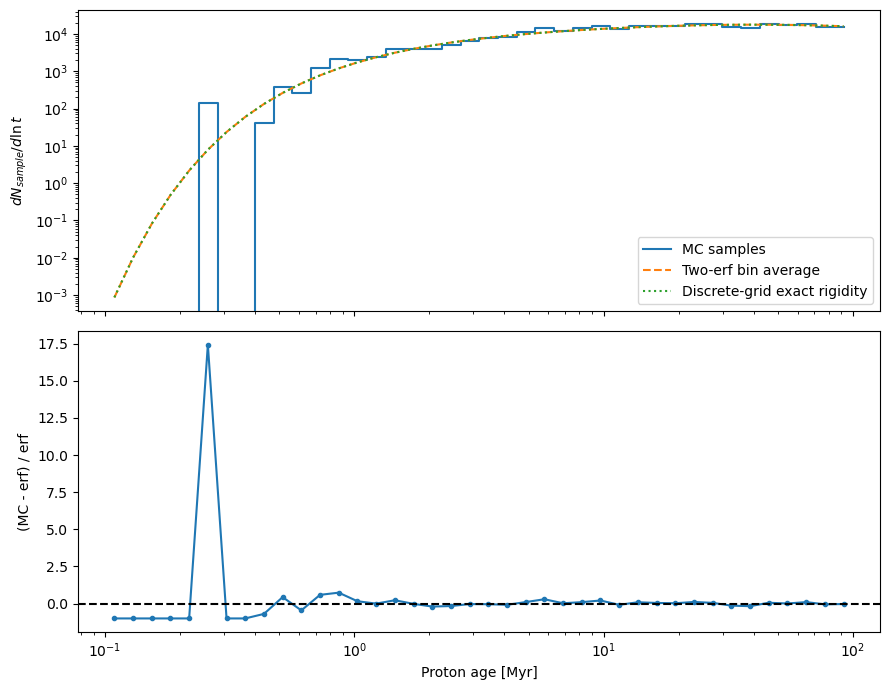

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].step(time_centers/1e6, observed, where='mid', label='MC samples')
axes[0].plot(time_centers/1e6, expected, '--', label='Two-erf bin average')
axes[0].plot(time_centers/1e6, exact_counts/dlnt, ':', label='Discrete-grid exact rigidity')
axes[0].set_yscale('log')
axes[0].set_ylabel(r'$dN_{sample}/d\ln t$')
axes[0].legend()

# Relative residuals are descriptive: repeat visits are correlated, so raw
# sample counts cannot supply independent Poisson uncertainties.
residual = (observed-expected)/expected
axes[1].plot(time_centers/1e6, residual, 'o-', markersize=3)
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set_ylabel('(MC - erf) / erf')
axes[1].set_xlabel('Proton age [Myr]')
axes[1].set_xscale('log')
fig.tight_layout()
plt.show()


The present run can show an early rise and a broad peak. Its duration may be too short for a clear late-time slope of −0.5; that limit requires t much larger than b/Dmin. Differences include finite particle statistics, correlated visits, finite-step diffusion, and the thin-torus approximation. The deterministic log-energy grid approximates the continuum E^-1 injection spectrum.


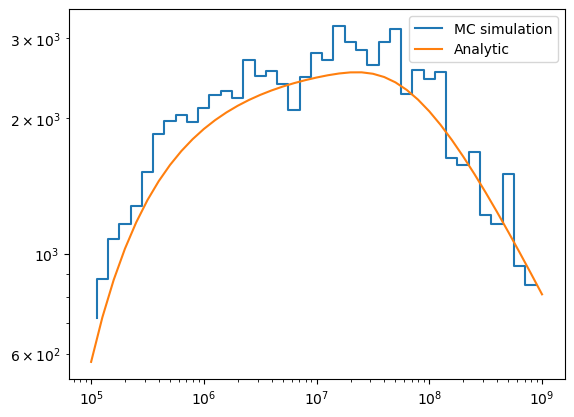

In [5]:
da = np.fromfile("proton_earth_t1e9_D0.5.bin", dtype='=f8').reshape(-1, 2)
lt = 41
time_bins = np.logspace(5, 9, lt)
time_centers = np.sqrt(time_bins[:-1]*time_bins[1:])
dlnt = np.diff(np.log(time_bins))
age = np.histogram(da[:,1], bins = time_bins)[0]

E_min = 10
E_max = 1e7
N_particles = 1e4
C = N_particles/np.log(E_max/E_min)
b = R_earth**2/4
delta = 1/2
D_min = c_pc_yr*2*(E_min/10)**delta/3
D_max = c_pc_yr*2*(E_max/10)**delta/3



slow = np.sqrt(b/(D_min*time_bins))
fast = np.sqrt(b/(D_max*time_bins))
expected = 3*np.pi*C/delta * (erf(slow)-erf(fast))

plt.step(time_centers, age, label = "MC simulation")
plt.plot(time_bins, expected / 5, label = "Analytic")

plt.xscale("log")
plt.yscale("log")
plt.legend()